In [19]:
import torch
import pandas as pd
import numpy
from sklearn.model_selection import train_test_split

In [20]:
df = pd.read_csv("../data/Clean_Dataset.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [21]:
df.columns

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='str')

In [22]:
df.isnull().sum()

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

In [23]:
df.columns

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='str')

In [24]:
y = df.price
X = df.drop(columns=['price', 'Unnamed: 0', 'flight'])
X.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,SpiceJet,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1
1,SpiceJet,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1
2,AirAsia,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1
3,Vistara,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1
4,Vistara,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1


In [25]:
cat_cols = ['airline', 'source_city', 'departure_time', 'stops',
            'arrival_time', 'destination_city', 'class']
X = pd.get_dummies(X, columns=cat_cols, dtype='float32')  # explicit columns, float32 to halve memory
X['duration'] = X['duration'].astype('float32')
X['days_left'] = X['days_left'].astype('float32')
X.shape

(300153, 37)

In [26]:
len(X.columns)

37

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### First we go with sklearn

In [10]:
!pip install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=2,
    tree_method="hist",
    device="cuda",
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=100,
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)

[0]	validation_0-rmse:22057.29405
[100]	validation_0-rmse:4377.89593
[200]	validation_0-rmse:3802.60230
[300]	validation_0-rmse:3559.00652
[400]	validation_0-rmse:3344.98704
[500]	validation_0-rmse:3191.50716
[600]	validation_0-rmse:3082.13843
[700]	validation_0-rmse:2998.55666
[800]	validation_0-rmse:2929.71996
[900]	validation_0-rmse:2868.40537
[1000]	validation_0-rmse:2810.67140
[1100]	validation_0-rmse:2761.24319
[1200]	validation_0-rmse:2718.90652
[1300]	validation_0-rmse:2679.18943
[1400]	validation_0-rmse:2649.35931
[1500]	validation_0-rmse:2623.65889
[1600]	validation_0-rmse:2599.48867
[1700]	validation_0-rmse:2580.68180
[1800]	validation_0-rmse:2558.79194
[1900]	validation_0-rmse:2540.52258
[1999]	validation_0-rmse:2523.48247


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.85
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [12]:
y_pred = model.predict(X_test)

c:\Users\Ayush\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\core.py:569: UserWarning: [17:18:37] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 1310.63671875
MSE: 6367967.0
R2 Score: 0.9876465797424316


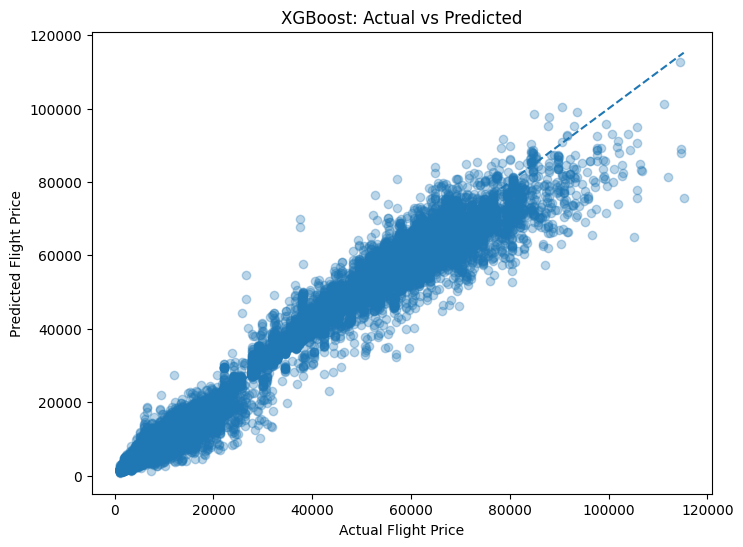

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("XGBoost: Actual vs Predicted")

plt.show()

In [15]:
!pip install catboost


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from catboost import CatBoostRegressor
model = CatBoostRegressor(
    task_type="GPU",
    iterations=500,
    devices="0"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Learning rate set to 0.125275
0:	learn: 20042.0642123	total: 131ms	remaining: 1m 5s
1:	learn: 17742.6478550	total: 140ms	remaining: 34.8s
2:	learn: 15754.4840345	total: 146ms	remaining: 24.1s
3:	learn: 14038.9685173	total: 152ms	remaining: 18.8s
4:	learn: 12566.7125894	total: 158ms	remaining: 15.7s
5:	learn: 11310.7539161	total: 164ms	remaining: 13.5s
6:	learn: 10231.6667636	total: 171ms	remaining: 12s
7:	learn: 9325.0477118	total: 177ms	remaining: 10.9s
8:	learn: 8558.8762411	total: 184ms	remaining: 10s
9:	learn: 7922.1708024	total: 190ms	remaining: 9.31s
10:	learn: 7390.5797410	total: 197ms	remaining: 8.74s
11:	learn: 6932.3087837	total: 203ms	remaining: 8.27s
12:	learn: 6553.3930619	total: 213ms	remaining: 7.97s
13:	learn: 6242.3475443	total: 225ms	remaining: 7.8s
14:	learn: 5992.8509859	total: 232ms	remaining: 7.5s
15:	learn: 5792.8034452	total: 239ms	remaining: 7.22s
16:	learn: 5630.6823095	total: 247ms	remaining: 7s
17:	learn: 5496.7135327	total: 254ms	remaining: 6.81s
18:	learn:

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2109.3874641818493
MSE: 13757133.319065697
R2 Score: 0.9733121117360253


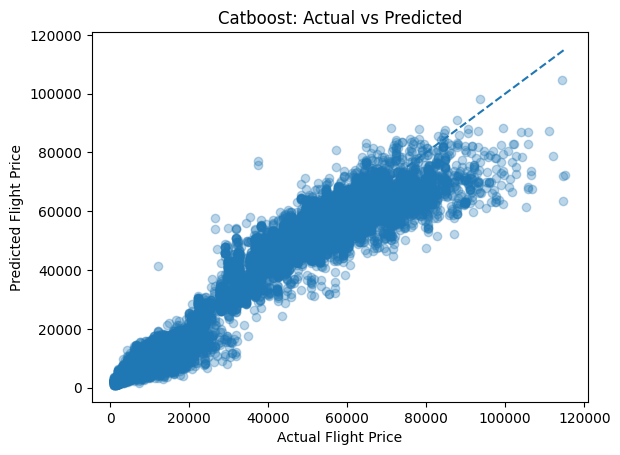

In [18]:
plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Catboost: Actual vs Predicted")

plt.show()

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [20]:
!pip install numpy


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [30]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

import numpy as np
# import torch

X_train = torch.tensor(
    np.asarray(X_train, dtype=np.float32),
    dtype=torch.float32
).to(device)

X_test = torch.tensor(
    np.asarray(X_test, dtype=np.float32),
    dtype=torch.float32
).to(device)

y_train = torch.tensor(
    y_train.to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)

y_test = torch.tensor(
    y_test.to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)

In [31]:
X.shape

(300153, 37)

In [32]:
device

device(type='cuda')

In [47]:
from torch import nn

class GharaNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(37, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256,1),
            # nn.ReLU(),
            # nn.Linear(64,1)
        )

    def forward(self, x):
        return self.network(x)

In [48]:
model = GharaNetwork().to(device)

In [100]:
criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.1
)

In [101]:
# model.load_state_dict(
#     torch.load(
#         "flight_price_model_01.pth",
#         map_location=device,
#         weights_only=True
#     )
# )

In [107]:
epochs = 200

for epoch in range(epochs):

    # Training mode
    model.train()

    # Forward propagation
    y_pred = model(X_train)

    # Calculate loss
    loss = criterion(y_pred, y_train)

    # Clear previous gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights and bias
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_pred = model(X_test)
        val_loss = criterion(val_pred, y_test)

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Val Loss: {val_loss.item():.4f}"
        )

Epoch [100/200] Train Loss: 1536.9492 Val Loss: 1767.2010
Epoch [200/200] Train Loss: 1518.6361 Val Loss: 1777.0338


In [108]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

model.eval()

with torch.no_grad():
    y_pred = model(X_test)

actual = y_test.cpu().numpy().flatten()
predicted = y_pred.cpu().numpy().flatten()

mse = mean_squared_error(actual, predicted)
mae = mean_absolute_error(actual, predicted)
r2 = r2_score(actual, predicted)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)
print("RMSE:", mse ** 0.5)

MSE: 13579259.0
MAE: 1777.0338134765625
R2 Score: 0.9736571907997131
RMSE: 3685.004613294263


In [ ]:
torch.save(
    model.state_dict(),
    "flight_price_model_02.pth"
)
# from torch import nn

# class GharaNetwork(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.network = nn.Sequential(
#             nn.Linear(37, 256),
#             nn.ReLU(),
#             nn.Linear(256, 256),
#             nn.ReLU(),
#             nn.Linear(256,1),
#             # nn.ReLU(),
#             # nn.Linear(64,1)
#         )

#     def forward(self, x):
#         return self.network(x)